In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df=pd.read_csv("clean_data_after_eda.csv")

In [4]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 44 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [5]:
df["date_activ"]=pd.to_datetime(df["date_activ"])
df["date_end"]=pd.to_datetime(df["date_end"])
df["date_modif_prod"]=pd.to_datetime(df["date_modif_prod"])
df["date_renewal"]=pd.to_datetime(df["date_renewal"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 44 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              14606 non-null  object        
 1   channel_sales                   14606 non-null  object        
 2   cons_12m                        14606 non-null  int64         
 3   cons_gas_12m                    14606 non-null  int64         
 4   cons_last_month                 14606 non-null  int64         
 5   date_activ                      14606 non-null  datetime64[ns]
 6   date_end                        14606 non-null  datetime64[ns]
 7   date_modif_prod                 14606 non-null  datetime64[ns]
 8   date_renewal                    14606 non-null  datetime64[ns]
 9   forecast_cons_12m               14606 non-null  float64       
 10  forecast_cons_year              14606 non-null  int64         
 11  fo

In [6]:
price=pd.read_csv("price_data.csv")

price["price_date"]=pd.to_datetime(price["price_date"])
price.info()
price.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   id                  193002 non-null  object        
 1   price_date          193002 non-null  datetime64[ns]
 2   price_off_peak_var  193002 non-null  float64       
 3   price_peak_var      193002 non-null  float64       
 4   price_mid_peak_var  193002 non-null  float64       
 5   price_off_peak_fix  193002 non-null  float64       
 6   price_peak_fix      193002 non-null  float64       
 7   price_mid_peak_fix  193002 non-null  float64       
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 11.8+ MB


,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [7]:
price

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.000000,0.000000,44.266931,0.00000,0.000000
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.000000,0.000000,44.266931,0.00000,0.000000
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.000000,0.000000,44.266931,0.00000,0.000000
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.000000,0.000000,44.266931,0.00000,0.000000
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.000000,0.000000,44.266931,0.00000,0.000000
...,...,...,...,...,...,...,...,...
192997,16f51cdc2baa19af0b940ee1b3dd17d5,2015-08-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555
192998,16f51cdc2baa19af0b940ee1b3dd17d5,2015-09-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555
192999,16f51cdc2baa19af0b940ee1b3dd17d5,2015-10-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555
193000,16f51cdc2baa19af0b940ee1b3dd17d5,2015-11-01,0.119916,0.102232,0.076257,40.728885,24.43733,16.291555


In [8]:
monthly_price_by_id=price.groupby(["id","price_date"]).agg({"price_off_peak_var":'mean',"price_off_peak_fix":'mean'}).reset_index()

# print(monthly_price_by_id)

jan_prices=monthly_price_by_id.groupby('id').first().reset_index()
dec_prices=monthly_price_by_id.groupby('id').last().reset_index()

merge_data=pd.merge(dec_prices.rename(columns={"price_off_peak_var":"dec_1","price_off_peak_fix":"dec_2"}),jan_prices.drop(columns="price_date"),on="id")
merge_data["offpeak_diff_dec_jan_energy"]=merge_data["dec_1"]-merge_data["price_off_peak_var"]
merge_data["offpeak_diff_dec_jan_power"]=merge_data["dec_2"]-merge_data["price_off_peak_fix"]

merge_data=merge_data[["id","offpeak_diff_dec_jan_energy","offpeak_diff_dec_jan_power"]]

merge_data.head()

,id,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power
0,0002203ffbb812588b632b9e628cc38d,-0.006192,0.162916
1,0004351ebdd665e6ee664792efc4fd13,-0.004104,0.177779
2,0010bcc39e42b3c2131ed2ce55246e3c,0.050443,1.500000
3,0010ee3855fdea87602a5b7aba8e42de,-0.010018,0.162916
4,00114d74e963e47177db89bc70108537,-0.003994,-0.000001


In [9]:
df=pd.merge(df,merge_data,on="id")
df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,9.084737e-04,2.086294,99.530517,44.235794,2.086425,9.953056e+01,4.423670e+01,1,0.020057,3.700961
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000000e+00,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000e+00,0,-0.003767,0.177779
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000000e+00,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000e+00,0,-0.004670,0.177779
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0.000000e+00,0.000000,0.000000,0.000000,0.000003,0.000000e+00,0.000000e+00,0,-0.004547,0.177779
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,4.860000e-10,0.000000,0.000000,0.000000,0.000011,2.896760e-06,4.860000e-10,0,-0.006192,0.162916


In [10]:
means=price.groupby("id").agg({"price_off_peak_var":"mean","price_peak_var":"mean","price_mid_peak_var":"mean","price_off_peak_fix":"mean","price_peak_fix":"mean","price_mid_peak_fix":"mean"})

In [11]:
means["off_peak_peak_var_mean_diff"]=means['price_off_peak_var']-means['price_peak_var']
means["peak_mid_peak_var_mean_diff"]=means['price_peak_var']-means['price_mid_peak_var']
means["off_peak_mid_peak_var_mean_diff"]=means['price_off_peak_var']-means['price_mid_peak_fix']
means["off_peak_peak_fix_mean_diff"]=means['price_off_peak_fix']-means['price_peak_fix']
means["peak_mid_peak_fix_mean_diff"]=means['price_peak_fix']-means['price_mid_peak_fix']
means["off_peak_mid_peak_fix_mean_diff"]=means['price_off_peak_fix']-means['price_mid_peak_fix']

In [12]:
max_diff_across_months=means.groupby("id").agg({
    "off_peak_peak_var_mean_diff":"max",
    "peak_mid_peak_var_mean_diff":"max",
    "off_peak_mid_peak_var_mean_diff":"max",
    "off_peak_peak_fix_mean_diff":"max",
    "peak_mid_peak_fix_mean_diff":"max",
    "off_peak_mid_peak_fix_mean_diff":"max"
}).reset_index().rename(
    columns={
        "off_peak_peak_var_mean_diff":"off_peak_peak_var_max_monthly_diff",
    "peak_mid_peak_var_mean_diff":"peak_mid_peak_var_max_monthly_diff",
    "off_peak_mid_peak_var_mean_diff":"off_peak_mid_peak_var_max_monthly_diff",
    "off_peak_peak_fix_mean_diff":"off_peak_peak_fix_max_monthly_diff",
    "peak_mid_peak_fix_mean_diff":"peak_mid_peak_fix_max_monthly_diff",
    "off_peak_mid_peak_fix_mean_diff":"off_peak_mid_fix_max_monthly_diff"
    }
)
max_diff_across_months

,id,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_fix_max_monthly_diff
0,0002203ffbb812588b632b9e628cc38d,0.020545,0.030633,-16.156356,16.280694,8.140345,24.421038
1,0004351ebdd665e6ee664792efc4fd13,0.146426,0.000000,0.146426,44.385450,0.000000,44.385450
2,0010bcc39e42b3c2131ed2ce55246e3c,0.181558,0.000000,0.181558,45.319710,0.000000,45.319710
3,0010ee3855fdea87602a5b7aba8e42de,0.020465,0.029260,-16.140214,16.258972,8.129484,24.388456
4,00114d74e963e47177db89bc70108537,0.147926,0.000000,0.147926,44.266930,0.000000,44.266930
...,...,...,...,...,...,...,...
16091,ffef185810e44254c3a4c6395e6b4d8a,0.023739,0.034344,-16.369109,16.258971,8.129484,24.388455
16092,fffac626da707b1b5ab11e8431a4d0a2,0.147137,0.000000,0.147137,44.311375,0.000000,44.311375
16093,fffc0cacd305dd51f316424bbb08d1bd,0.024382,0.034655,-16.609691,16.264402,8.132199,24.396601
16094,fffe4f5646aa39c7f97f95ae2679ce64,0.020359,0.029764,-16.118820,16.242682,8.121339,24.364021


In [13]:
columns=[
    "id",
    "off_peak_peak_var_max_monthly_diff",
    "peak_mid_peak_var_max_monthly_diff",
    "off_peak_mid_peak_var_max_monthly_diff",
    "off_peak_peak_fix_max_monthly_diff",
    "peak_mid_peak_fix_max_monthly_diff",
    "off_peak_mid_fix_max_monthly_diff"
]

df=pd.merge(df,max_diff_across_months[columns],on="id")

df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_mid_peak,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_fix_max_monthly_diff
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,4.423670e+01,1,0.020057,3.700961,0.024038,0.034219,-14.776553,18.590255,7.450670,26.040925
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000000e+00,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.000000,44.311375
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000000e+00,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.000000,44.385450
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0.000000e+00,0,-0.004547,0.177779,0.151210,0.000000,0.151210,44.400265,0.000000,44.400265
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,4.860000e-10,0,-0.006192,0.162916,0.020536,0.030773,-16.151089,16.275263,8.137629,24.412893


In [14]:
df["tenure"]=(df["date_end"]-df["date_activ"]).dt.days//365

df.head()


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_fix_max_monthly_diff,tenure
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,1,0.020057,3.700961,0.024038,0.034219,-14.776553,18.590255,7.450670,26.040925,3
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.000000,44.311375,7
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.000000,44.385450,6
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0,-0.004547,0.177779,0.151210,0.000000,0.151210,44.400265,0.000000,44.400265,6
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,0,-0.006192,0.162916,0.020536,0.030773,-16.151089,16.275263,8.137629,24.412893,6


In [15]:
lets_see_corr=df.groupby("tenure").agg({"churn":"mean"})

lets_see_corr

,churn
tenure,
2,0.176471
3,0.143874
4,0.127473
5,0.091999
6,0.075407
7,0.075472
8,0.047244
9,0.012500
10,0.045455


In [16]:
def convert_months(reference_date,df,column):

  
    years=reference_date.year-df[column].dt.year
    month=reference_date.month-df[column].dt.month

    months=years*12-month

    months-=(reference_date.day<df[column].dt.day).astype(int)

    return months



In [17]:
ref_date=pd.to_datetime("2016-01-01")

# ref_date
df["months_activ"]=convert_months(ref_date,df,"date_activ")
df["months_end"]=convert_months(ref_date,df,"date_end")
df["months_modif_prod"]=convert_months(ref_date,df,"date_modif_prod")
df["months_renewal"]=convert_months(ref_date,df,"date_renewal")

df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_fix_max_monthly_diff,tenure,months_activ,months_end,months_modif_prod,months_renewal
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.034219,-14.776553,18.590255,7.450670,26.040925,3,40,4,22,16
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.007124,0.149609,44.311375,0.000000,44.311375,7,90,6,90,18
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.088421,0.170512,44.385450,0.000000,44.385450,6,74,2,74,14
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0.000000,0.151210,44.400265,0.000000,44.400265,6,73,1,73,13
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,0.030773,-16.151089,16.275263,8.137629,24.412893,6,71,1,71,13


In [18]:
df=df.drop(columns=["date_activ","date_end","date_modif_prod","months_renewal"])

In [19]:
df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,...,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_fix_max_monthly_diff,tenure,months_activ,months_end,months_modif_prod
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2015-06-23,0.00,0,0.0,1.78,...,0.024038,0.034219,-14.776553,18.590255,7.450670,26.040925,3,40,4,22
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2015-08-31,189.95,0,0.0,16.27,...,0.142485,0.007124,0.149609,44.311375,0.000000,44.311375,7,90,6,90
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2015-04-17,47.96,0,0.0,38.72,...,0.082090,0.088421,0.170512,44.385450,0.000000,44.385450,6,74,2,74
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2015-03-31,240.04,0,0.0,19.83,...,0.151210,0.000000,0.151210,44.400265,0.000000,44.400265,6,73,1,73
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2015-03-09,445.75,526,0.0,131.73,...,0.020536,0.030773,-16.151089,16.275263,8.137629,24.412893,6,71,1,71


In [20]:
df["has_gas"]=df["has_gas"].replace(['t','f'],[1,0])
df.groupby("has_gas").churn.mean()

C:\Users\KIIT\AppData\Local\Temp\ipykernel_2696\4008816429.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["has_gas"]=df["has_gas"].replace(['t','f'],[1,0])


has_gas
0    0.100544
1    0.081856
Name: churn, dtype: float64

In [21]:
df.loc[:,["channel_sales","origin_up"]]

,channel_sales,origin_up
0,foosdfpfkusacimwkcsosbicdxkicaua,lxidpiddsbxsbosboudacockeimpuepw
1,MISSING,kamkkxfxxuwbdslkwifmmcsiusiuosws
2,foosdfpfkusacimwkcsosbicdxkicaua,kamkkxfxxuwbdslkwifmmcsiusiuosws
3,lmkebamcaaclubfxadlmueccxoimlema,kamkkxfxxuwbdslkwifmmcsiusiuosws
4,MISSING,kamkkxfxxuwbdslkwifmmcsiusiuosws
...,...,...
14601,foosdfpfkusacimwkcsosbicdxkicaua,lxidpiddsbxsbosboudacockeimpuepw
14602,foosdfpfkusacimwkcsosbicdxkicaua,lxidpiddsbxsbosboudacockeimpuepw
14603,foosdfpfkusacimwkcsosbicdxkicaua,lxidpiddsbxsbosboudacockeimpuepw
14604,foosdfpfkusacimwkcsosbicdxkicaua,lxidpiddsbxsbosboudacockeimpuepw


In [22]:
cols = ['channel_sales', 'origin_up']
min_count = 100

# get counts per category so we can filter out rare categories
value_counts = {col: df[col].value_counts() for col in cols}

df = pd.get_dummies(df, columns=cols, prefix=cols, dtype=int)



# drop rare columns
for col in cols:
    keep_cols = set(value_counts[col][value_counts[col] >= min_count].index.astype(str))

    dummy_cols = [c for c in df.columns if c.startswith(f"{col}_")]
    drop_cols = [c for c in dummy_cols if c.split(f"{col}_", 1)[1] not in keep_cols]
    df.drop(columns=drop_cols, inplace=True)


df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,...,months_end,months_modif_prod,channel_sales_MISSING,channel_sales_ewpakwlliwisiwduibdlfmalxowmwpci,channel_sales_foosdfpfkusacimwkcsosbicdxkicaua,channel_sales_lmkebamcaaclubfxadlmueccxoimlema,channel_sales_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0,54946,0,2015-06-23,0.00,0,0.0,1.78,0.114481,...,4,22,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,4660,0,0,2015-08-31,189.95,0,0.0,16.27,0.145711,...,6,90,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,544,0,0,2015-04-17,47.96,0,0.0,38.72,0.165794,...,2,74,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,1584,0,0,2015-03-31,240.04,0,0.0,19.83,0.146694,...,1,73,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,4425,0,526,2015-03-09,445.75,526,0.0,131.73,0.116900,...,1,71,1,0,0,0,0,1,0,0


In [23]:
skewed_cols=['cons_12m', 
    'cons_gas_12m', 
    'cons_last_month',
    'forecast_cons_12m', 
    'forecast_cons_year', 
    'forecast_discount_energy',
    'forecast_meter_rent_12m', 
    'forecast_price_energy_off_peak',
    'forecast_price_energy_peak', 
    'forecast_price_pow_off_peak']

print("Before")
ans=df[skewed_cols].skew()
print(ans)

df[skewed_cols]=np.log10(df[skewed_cols]+1)

print("After")
ans=df[skewed_cols].skew()
print(ans)


Before
cons_12m                           5.997308
cons_gas_12m                       9.597530
cons_last_month                    6.391407
forecast_cons_12m                  7.155853
forecast_cons_year                16.587990
forecast_discount_energy           5.155098
forecast_meter_rent_12m            1.505148
forecast_price_energy_off_peak    -0.119586
forecast_price_energy_peak        -0.014331
forecast_price_pow_off_peak       -4.998772
dtype: float64
After
cons_12m                          -0.379541
cons_gas_12m                       1.875725
cons_last_month                   -0.190697
forecast_cons_12m                 -2.032752
forecast_cons_year                -0.118649
forecast_discount_energy           5.069118
forecast_meter_rent_12m           -0.603638
forecast_price_energy_off_peak    -0.466443
forecast_price_energy_peak        -0.021378
forecast_price_pow_off_peak      -11.630457
dtype: float64


In [24]:
import seaborn as sns

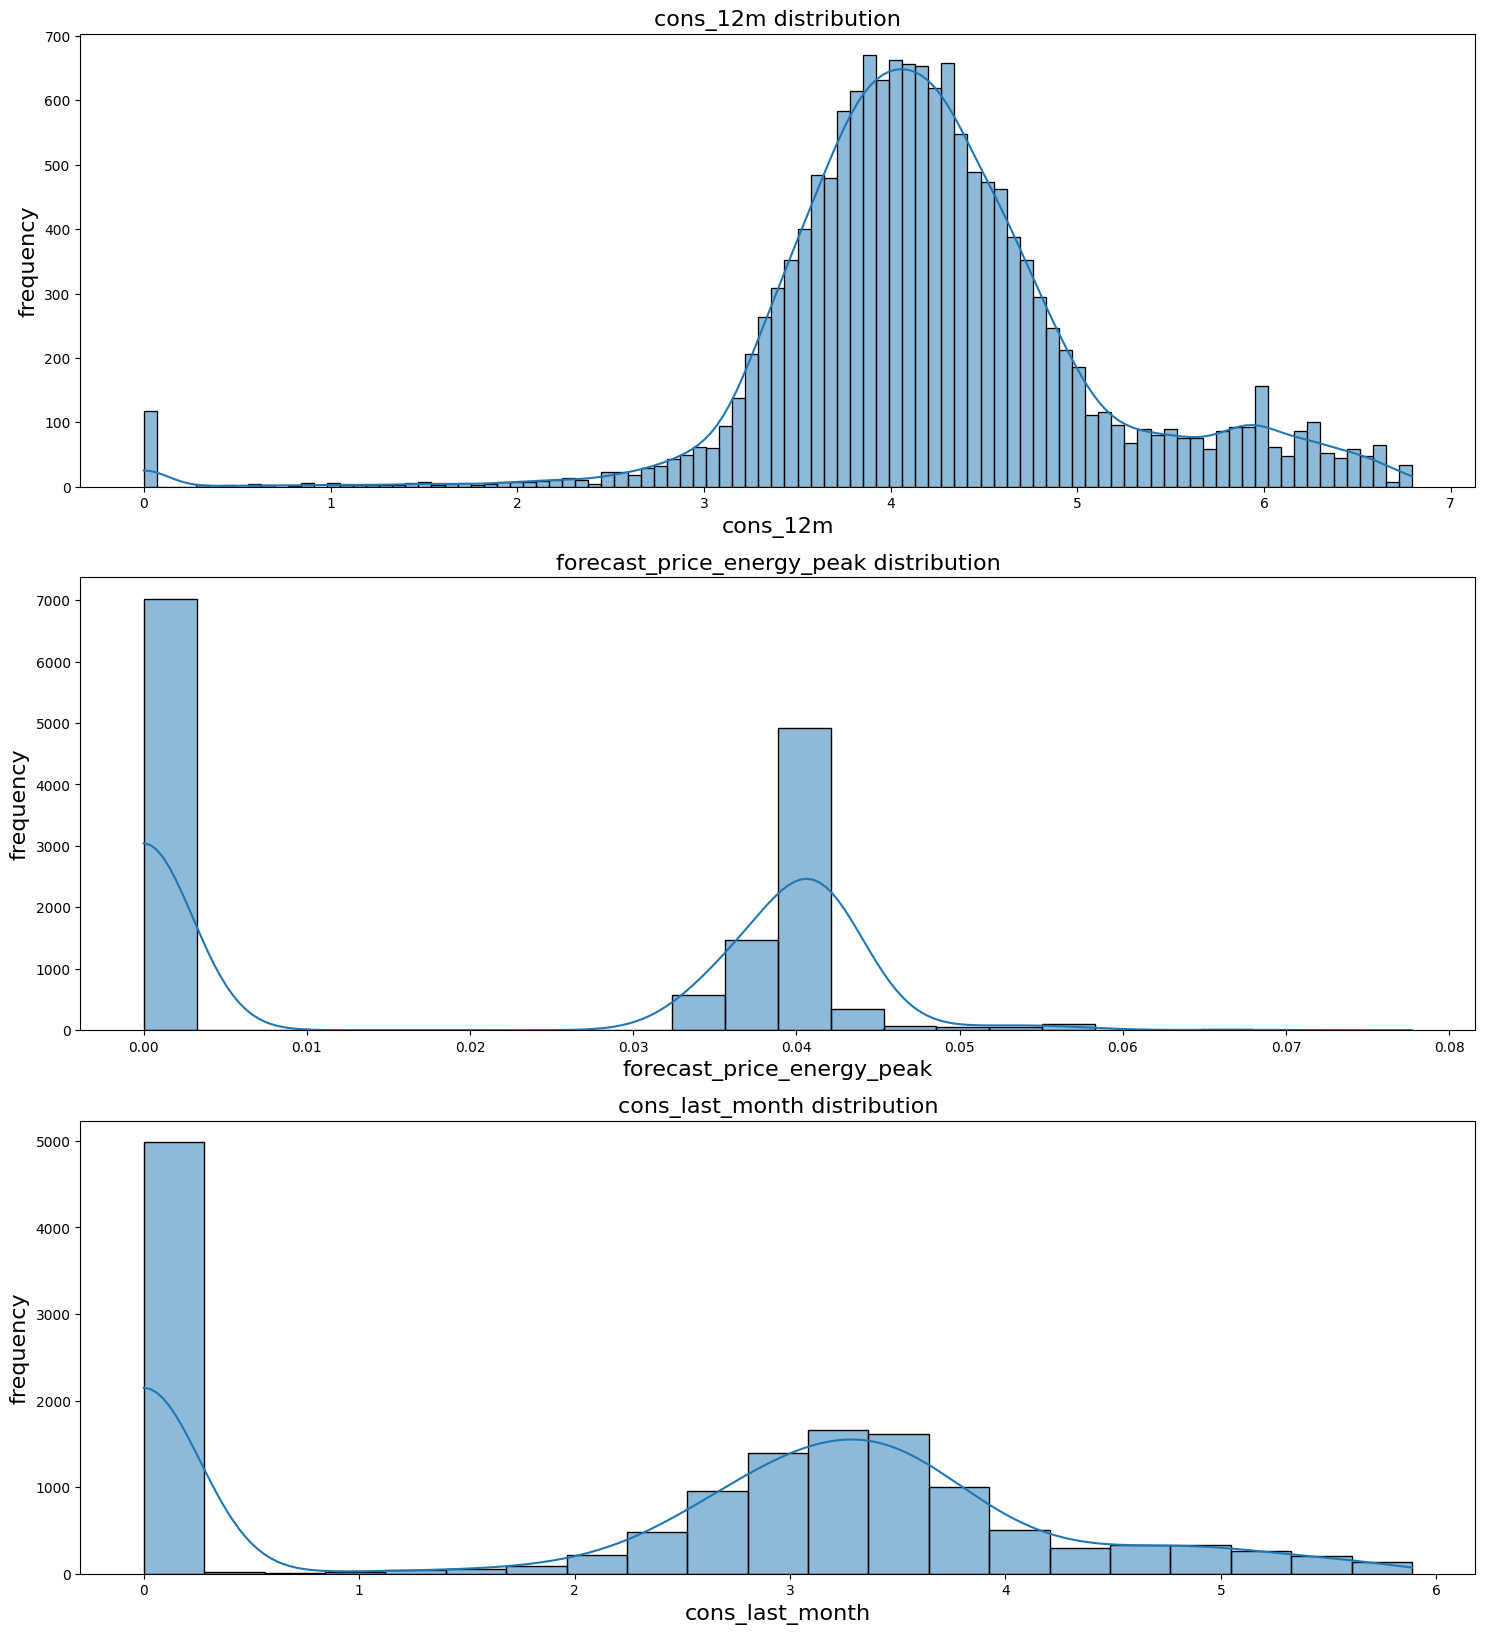

In [25]:
cols=["cons_12m","forecast_price_energy_peak","cons_last_month"]

fig,axs=plt.subplots(nrows=3,figsize=(18,20))

for ax,col in zip(axs,cols):
    sns.histplot(df[col].dropna(),kde=True,ax=ax)
    ax.set_title(f"{col} distribution",fontsize=16)
    ax.set_xlabel(f"{col}",fontsize=16)
    ax.set_ylabel("frequency",fontsize=16)


In [35]:
correlation=df.drop(columns="id").corr()

correlation

,cons_12m,cons_gas_12m,cons_last_month,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,...,months_end,months_modif_prod,channel_sales_MISSING,channel_sales_ewpakwlliwisiwduibdlfmalxowmwpci,channel_sales_foosdfpfkusacimwkcsosbicdxkicaua,channel_sales_lmkebamcaaclubfxadlmueccxoimlema,channel_sales_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
cons_12m,1.000000,0.209637,0.623493,-0.079728,0.557186,0.321928,-0.027536,0.201488,-0.143048,0.278308,...,-0.057272,0.062496,-0.084505,-0.064549,-0.021040,0.300029,-0.125876,0.032191,-0.026175,-0.006561
cons_gas_12m,0.209637,1.000000,0.171077,0.004236,0.108450,0.084575,0.002409,0.063462,-0.040762,0.075662,...,-0.003322,0.019605,0.030565,-0.008177,-0.046458,0.048664,-0.014001,0.000443,0.001582,-0.002899
cons_last_month,0.623493,0.171077,1.000000,-0.069176,0.292725,0.786051,-0.013864,0.326362,-0.235679,0.396797,...,-0.061537,0.042215,-0.058077,-0.066062,0.010777,0.205685,-0.111115,-0.031805,-0.023550,0.049516
date_renewal,-0.079728,0.004236,-0.069176,1.000000,-0.098062,-0.054129,-0.183953,-0.041549,-0.079073,-0.061888,...,0.161755,0.040306,0.079003,-0.060171,-0.040617,-0.035090,0.042751,0.058015,-0.011989,-0.043160
forecast_cons_12m,0.557186,0.108450,0.292725,-0.098062,1.000000,0.361325,0.057713,0.222187,0.058293,0.220166,...,-0.003605,-0.107274,-0.099932,-0.006704,0.055963,0.081416,-0.034369,-0.031513,-0.020166,0.046185
forecast_cons_year,0.321928,0.084575,0.786051,-0.054129,0.361325,1.000000,0.015979,0.391082,-0.295384,0.431254,...,-0.055083,-0.032968,-0.035257,-0.034238,0.057864,0.038128,-0.062021,-0.097037,-0.012083,0.099111
forecast_discount_energy,-0.027536,0.002409,-0.013864,-0.183953,0.057713,0.015979,1.000000,-0.004132,0.341919,0.057972,...,-0.032993,-0.182361,-0.039652,-0.009355,0.056117,-0.053219,0.032279,-0.061712,-0.030648,0.080225
forecast_meter_rent_12m,0.201488,0.063462,0.326362,-0.041549,0.222187,0.391082,-0.004132,1.000000,-0.423002,0.651167,...,-0.012049,-0.029312,-0.008968,-0.006481,0.035963,0.018300,-0.062369,-0.058502,0.053057,0.010821
forecast_price_energy_off_peak,-0.143048,-0.040762,-0.235679,-0.079073,0.058293,-0.295384,0.341919,-0.423002,1.000000,-0.330108,...,0.033034,-0.083385,-0.078563,0.018950,-0.004248,0.011807,0.095862,0.121756,-0.081894,-0.044282
forecast_price_energy_peak,0.278308,0.075662,0.396797,-0.061888,0.220166,0.431254,0.057972,0.651167,-0.330108,1.000000,...,-0.015010,0.018850,0.019082,-0.017604,-0.021287,0.093223,-0.083456,-0.007044,0.054319,-0.039169


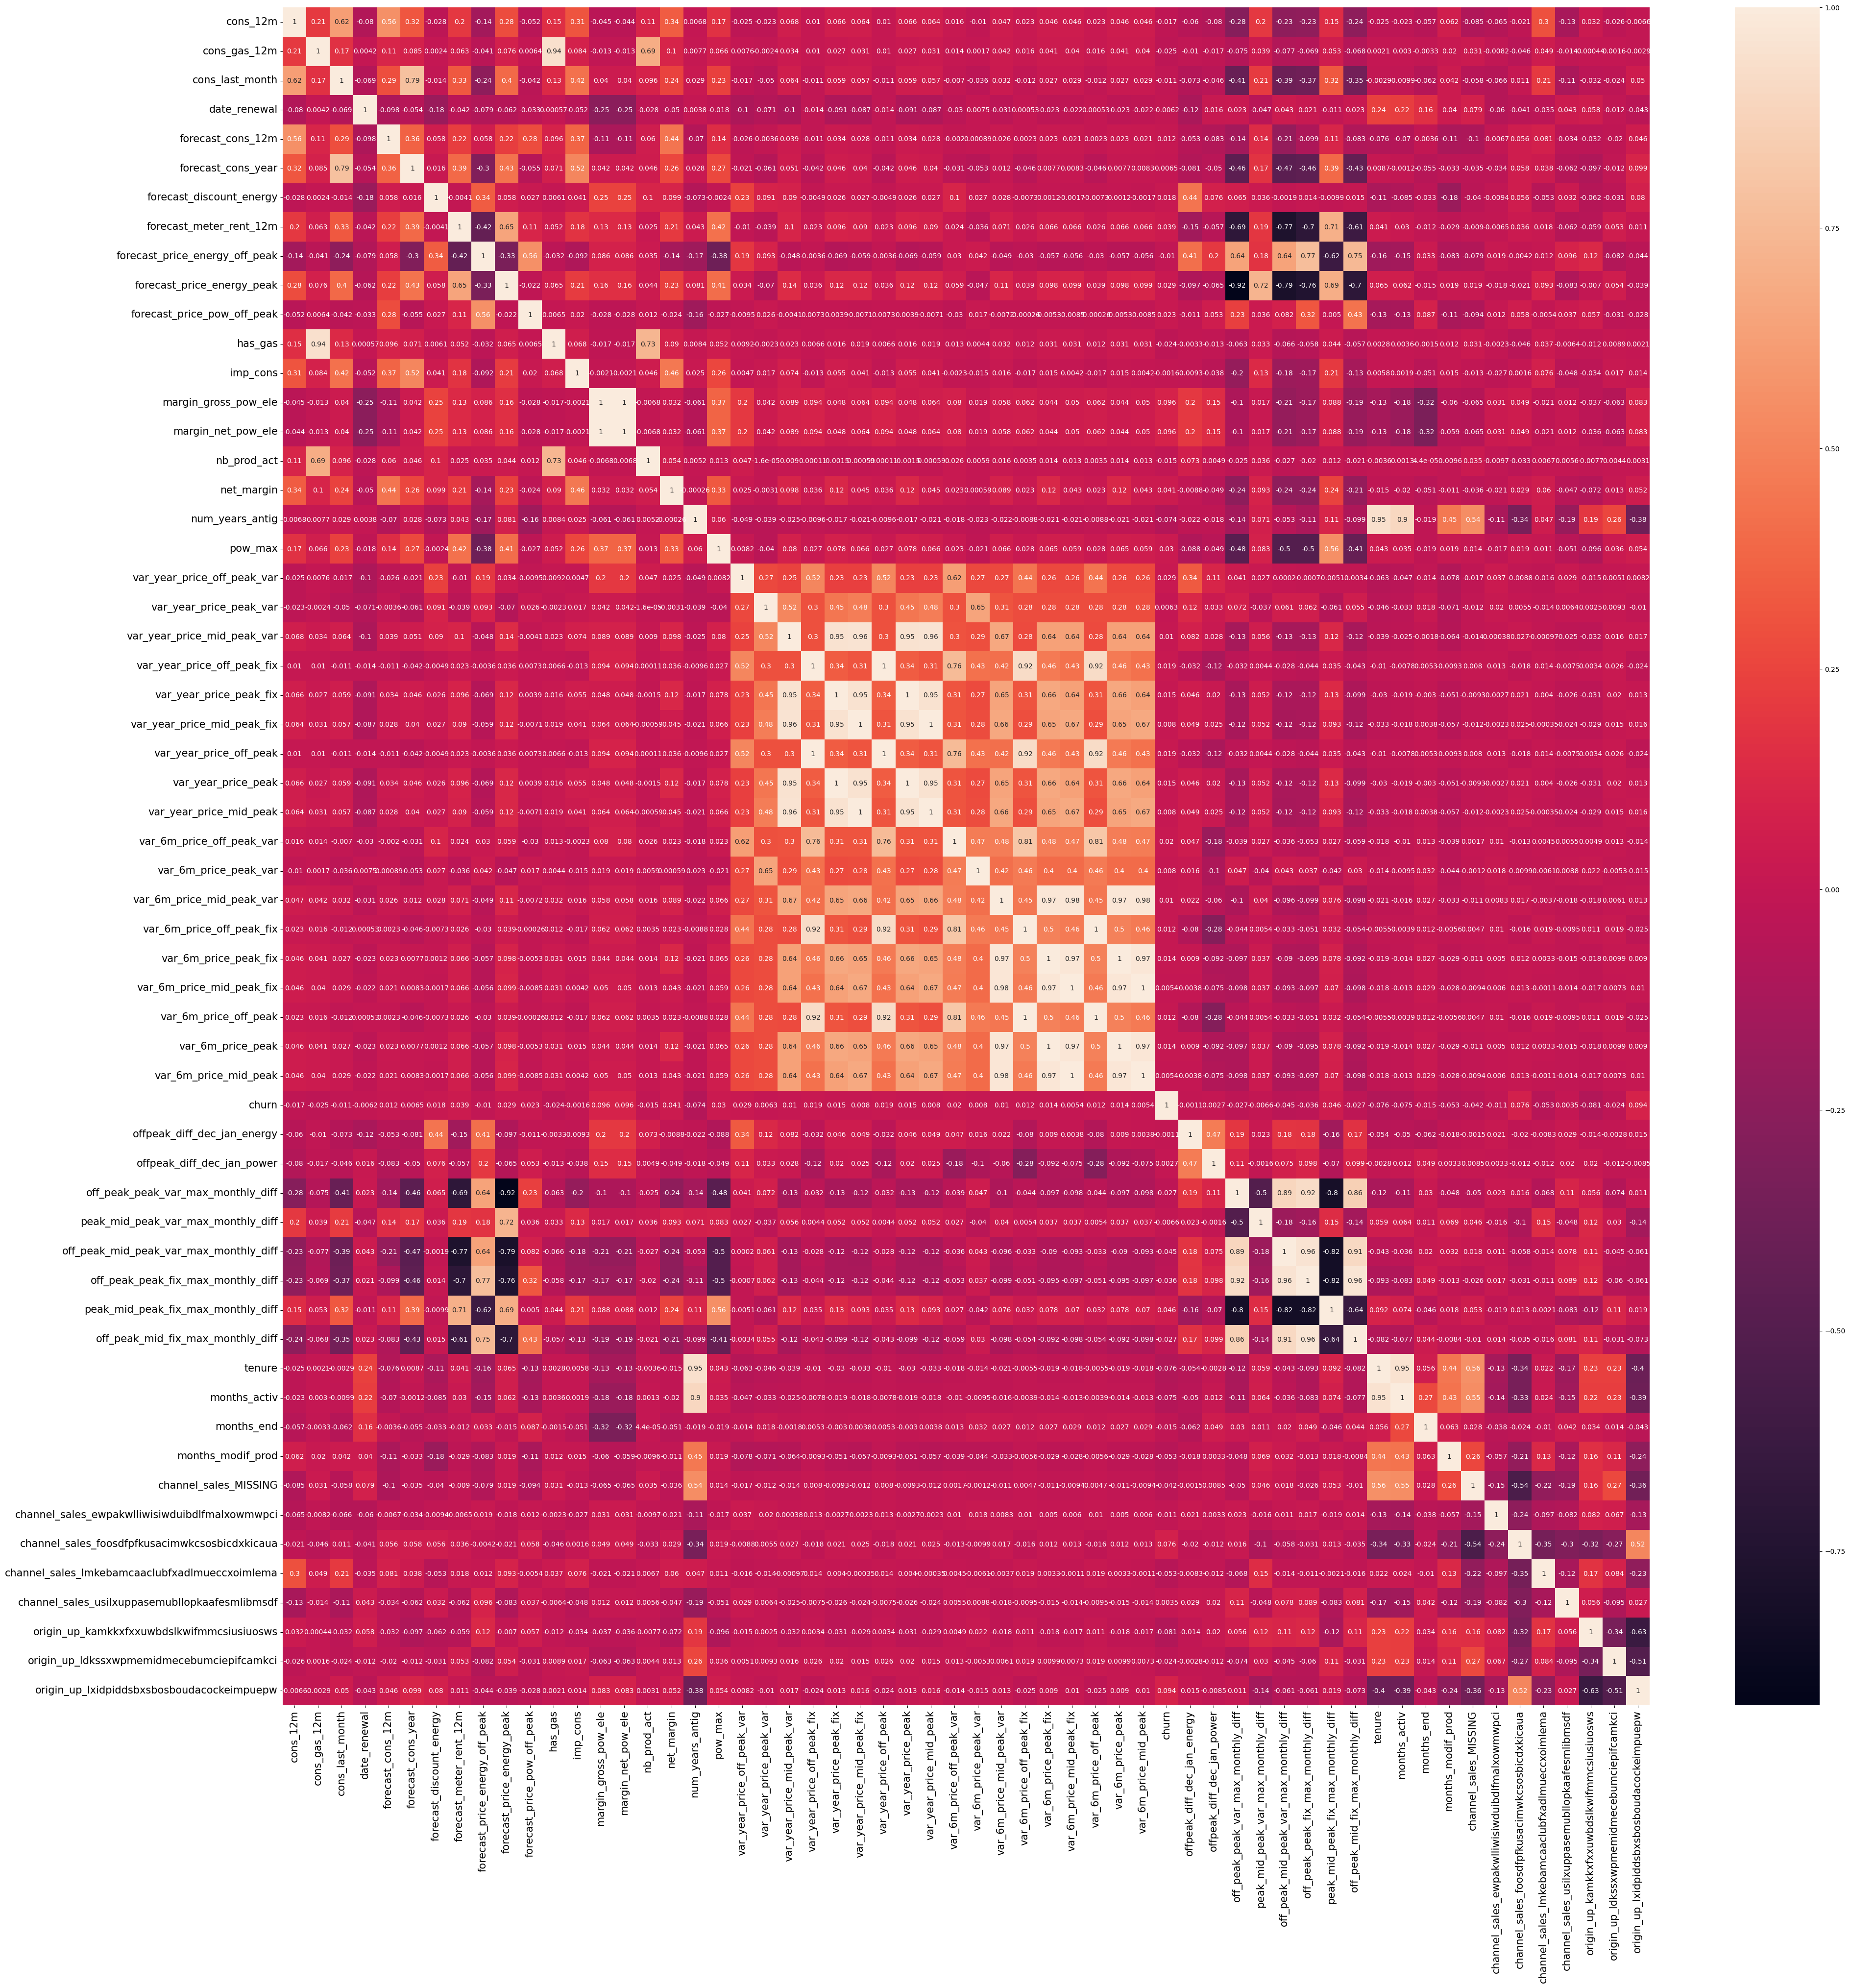

In [34]:
plt.figure(figsize=(45,45))
sns.heatmap(correlation,xticklabels=correlation.columns.values,yticklabels=correlation.columns.values,annot=True)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.show()